# Progres 2 — Eksplorasi Data, Uji Stasioneritas, dan Visualisasi
**Tujuan:**
1. Memahami pola deret realisasi BPHTB: tren, musiman, variasi, dan nilai ekstrem.
2. Menentukan transformasi dan menguji stasioneritas (ADF dan KPSS) beserta visualisasinya.
3. Membaca ACF/PACF untuk menduga orde awal SARIMA.
4. Menetapkan pembagian data latih dan uji.

**Input:** `bphtb_bulanan.csv`, `target_bphtb.csv` (dari Progres 1)
**Output:** `indeks_musiman.csv`, `hasil_uji_stasioneritas.csv`, `pembagian_data.json`

In [2]:
# ===== Pengaturan file (VS Code / Jupyter lokal) =====
# Semua file input dan output berada di folder yang sama dengan notebook ini.
# Jalankan dulu progres sebelumnya agar file yang dibutuhkan sudah tersedia.
# Library yang diperlukan (cukup sekali, di terminal dengan venv aktif):
#   pip install pandas numpy matplotlib scipy scikit-learn statsmodels openpyxl ipykernel
import os

def pastikan_file(nama):
    """Hentikan notebook dengan pesan jelas jika file input belum ada."""
    if not os.path.exists(nama):
        raise FileNotFoundError(
            f"File '{nama}' tidak ditemukan di folder {os.getcwd()}. "
            "Pastikan file ada di folder yang sama dengan notebook, "
            "atau jalankan progres sebelumnya terlebih dahulu.")

def unduh(*nama_file):
    """Di VS Code file sudah tersimpan di folder kerja; cukup tampilkan daftarnya."""
    for f in nama_file:
        print("Tersimpan:", os.path.abspath(f))

In [3]:
import warnings; warnings.filterwarnings("ignore")
import json, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (11, 4)

In [4]:
pastikan_file("bphtb_bulanan.csv")
y = pd.read_csv("bphtb_bulanan.csv", index_col="bulan", parse_dates=True)["realisasi_miliar"].asfreq("MS")
print(len(y), "bulan:", y.index[0].strftime("%b %Y"), "–", y.index[-1].strftime("%b %Y"))

68 bulan: Jan 2021 – Aug 2026


## 2.1 Statistik deskriptif

In [5]:
print(y.describe().round(2))
tabel = y.rename_axis("tanggal").to_frame("y").assign(tahun=y.index.year, bulan=y.index.month)
ringkas = tabel.groupby("tahun")["y"].agg(jumlah="sum", rata2="mean", simpangan="std", min="min", max="max", n="count")
ringkas["CV (%)"] = ringkas["simpangan"] / ringkas["rata2"] * 100
ringkas.round(1)

count     68.00
mean     110.89
std       57.67
min       22.44
25%       76.71
50%       98.51
75%      117.41
max      279.74
Name: realisasi_miliar, dtype: float64


,jumlah,rata2,simpangan,min,max,n,CV (%)
tahun,,,,,,,
2021,1291.2,107.6,55.9,22.4,246.2,12,52.0
2022,1280.8,106.7,57.1,39.3,268.6,12,53.5
2023,1414.2,117.8,68.4,44.3,267.4,12,58.1
2024,1342.0,111.8,59.9,60.1,279.7,12,53.5
2025,1418.3,118.2,53.8,44.2,224.0,12,45.5
2026,794.3,99.3,62.2,51.4,245.4,8,62.6


## 2.2 Plot deret waktu

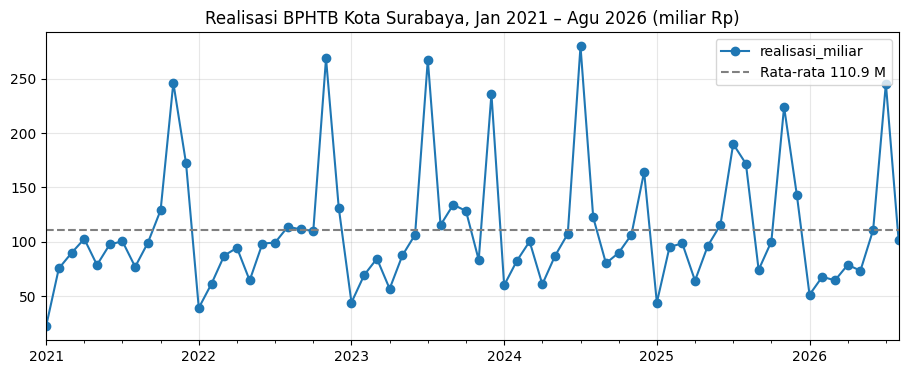

In [6]:
fig, ax = plt.subplots()
y.plot(ax=ax, marker="o")
ax.axhline(y.mean(), ls="--", color="gray", label=f"Rata-rata {y.mean():.1f} M")
ax.set_title("Realisasi BPHTB Kota Surabaya, Jan 2021 – Agu 2026 (miliar Rp)")
ax.set_xlabel(""); ax.legend(); ax.grid(alpha=.3); plt.show()

## 2.3 Realisasi vs target tahunan

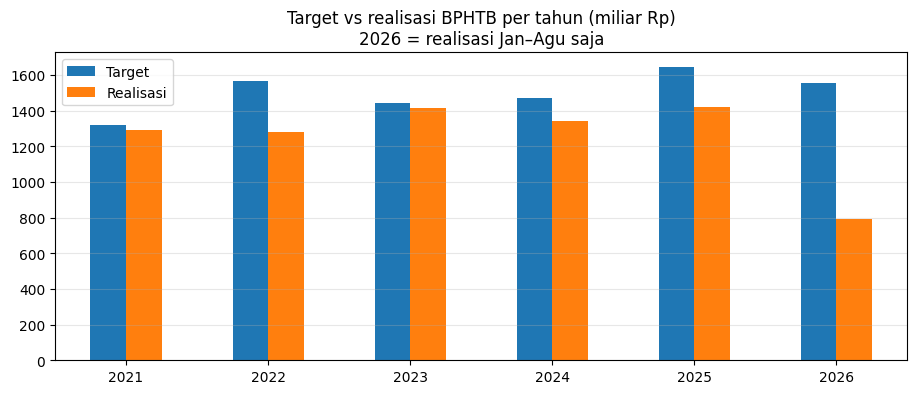

,Target,Realisasi,Capaian (%)
2021,1320.1,1291.2,97.8
2022,1565.5,1280.8,81.8
2023,1442.5,1414.2,98.0
2024,1469.8,1342.0,91.3
2025,1645.1,1418.3,86.2
2026,1556.5,794.3,51.0


In [7]:
pastikan_file("target_bphtb.csv")
target = pd.read_csv("target_bphtb.csv", index_col="tahun")["target_miliar"]
tahunan = pd.DataFrame({"Target": target, "Realisasi": y.groupby(y.index.year).sum()})
tahunan["Capaian (%)"] = tahunan["Realisasi"] / tahunan["Target"] * 100
tahunan[["Target", "Realisasi"]].plot.bar(title="Target vs realisasi BPHTB per tahun (miliar Rp)\n2026 = realisasi Jan–Agu saja")
plt.xticks(rotation=0); plt.grid(alpha=.3, axis="y"); plt.show()
tahunan.round(1)

## 2.4 Pola musiman

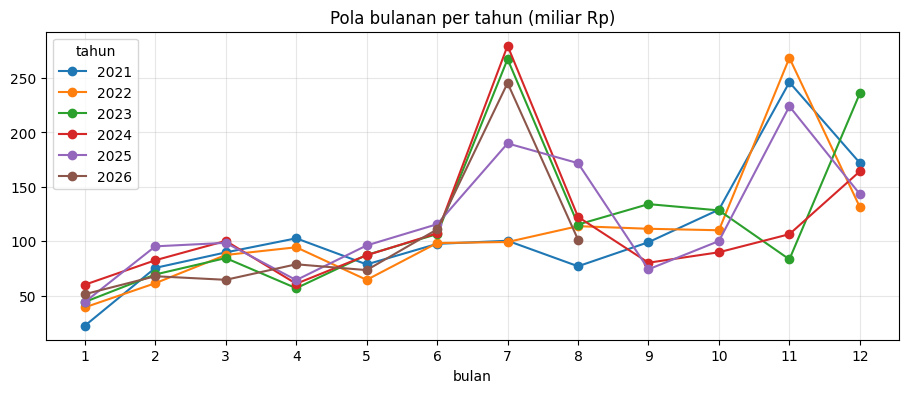

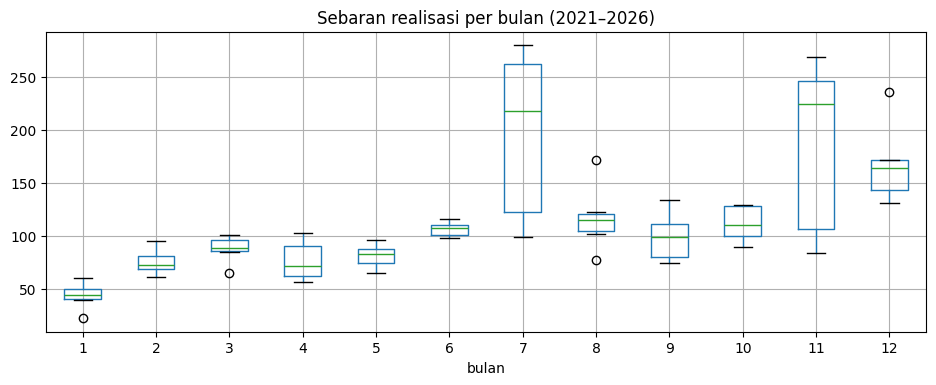

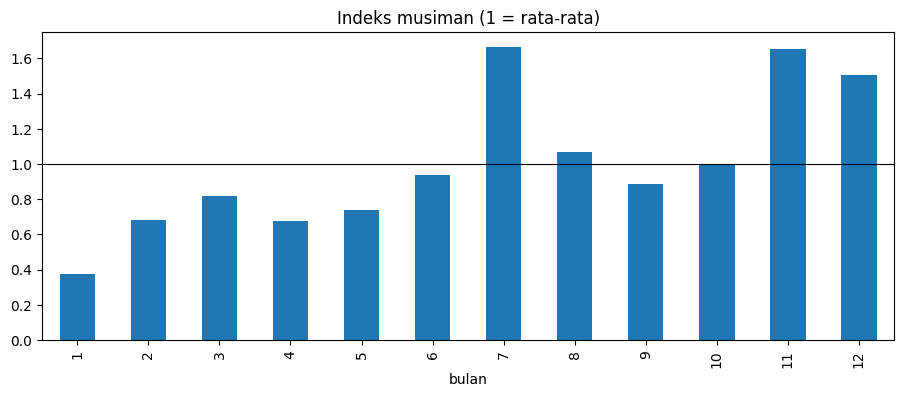

bulan
1     0.37
2     0.68
3     0.82
4     0.68
5     0.74
6     0.94
7     1.67
8     1.07
9     0.89
10    0.99
11    1.65
12    1.51
Name: y, dtype: float64

In [8]:
pv = tabel.pivot(index="bulan", columns="tahun", values="y")
pv.plot(marker="o", title="Pola bulanan per tahun (miliar Rp)")
plt.xticks(range(1, 13)); plt.grid(alpha=.3); plt.show()

tabel.boxplot(column="y", by="bulan"); plt.suptitle("")
plt.title("Sebaran realisasi per bulan (2021–2026)"); plt.show()

# indeks musiman: rata-rata bulan / rata-rata keseluruhan (memakai tahun lengkap 2021–2025)
lengkap = tabel[tabel.tahun <= 2025]
indeks = lengkap.groupby("bulan")["y"].mean() / lengkap["y"].mean()
indeks.rename("indeks_musiman").to_csv("indeks_musiman.csv")
indeks.plot.bar(title="Indeks musiman (1 = rata-rata)"); plt.axhline(1, color="k", lw=.8); plt.show()
indeks.round(2)

## 2.5 Nilai ekstrem (pencilan)
Pencilan diidentifikasi dari rasio terhadap rata-rata bulan yang sama di tahun lain (lebih dari 1,5× atau kurang dari 0,5×).

In [9]:
rata_bulan_lain = tabel.apply(lambda r: tabel[(tabel.bulan == r.bulan) & (tabel.tahun != r.tahun)]["y"].mean(), axis=1)
tabel["rasio_thd_tahun_lain"] = tabel["y"] / rata_bulan_lain
pencilan = tabel[(tabel.rasio_thd_tahun_lain > 1.5) | (tabel.rasio_thd_tahun_lain < 0.5)]
pencilan.round(2)

,y,tahun,bulan,rasio_thd_tahun_lain
tanggal,,,,
2021-01-01,22.44,2021,1,0.47
2021-07-01,100.53,2021,7,0.46
2022-07-01,99.37,2022,7,0.46
2022-11-01,268.59,2022,11,1.63
2023-11-01,83.42,2023,11,0.39
2023-12-01,235.92,2023,12,1.54
2024-07-01,279.74,2024,7,1.55
2025-08-01,171.81,2025,8,1.62


## 2.6 Dekomposisi
Dekomposisi multiplikatif memisahkan tren, musiman, dan sisa.

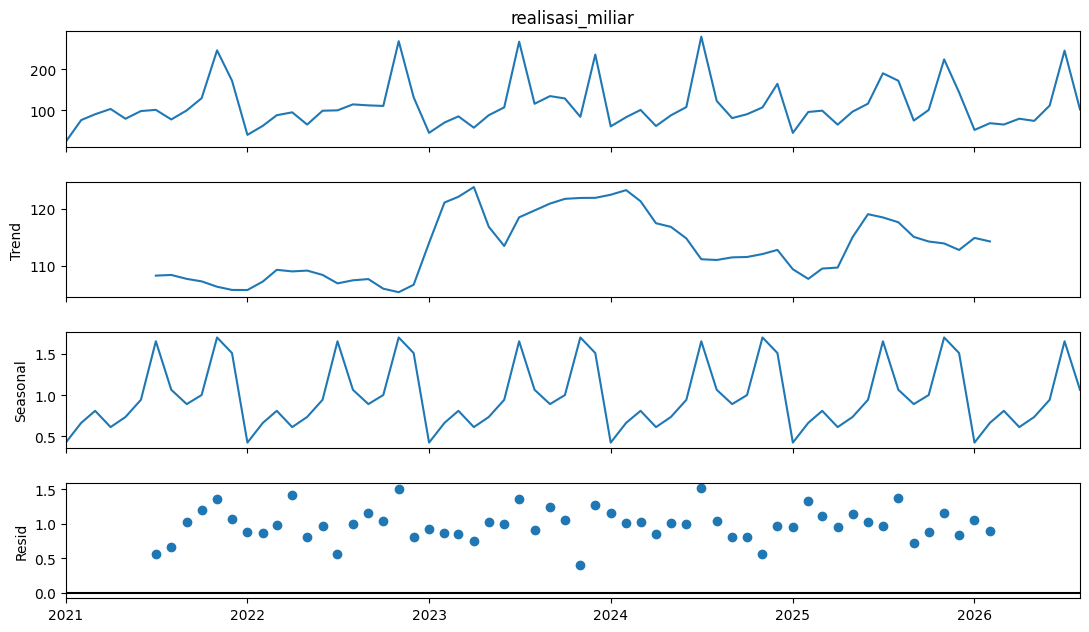

In [10]:
from statsmodels.tsa.seasonal import seasonal_decompose
dek = seasonal_decompose(y, model="multiplicative", period=12)
dek.plot(); plt.gcf().set_size_inches(11, 7); plt.show()

In [11]:
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

## 2.7 Transformasi log
Jika simpangan baku per tahun ikut membesar bersama rata-ratanya, transformasi log membantu menstabilkan varians.

        mean   std
bulan             
2021   107.6  55.9
2022   106.7  57.1
2023   117.8  68.4
2024   111.8  59.9
2025   118.2  53.8
Korelasi rata-rata vs simpangan baku tahunan: 0.374


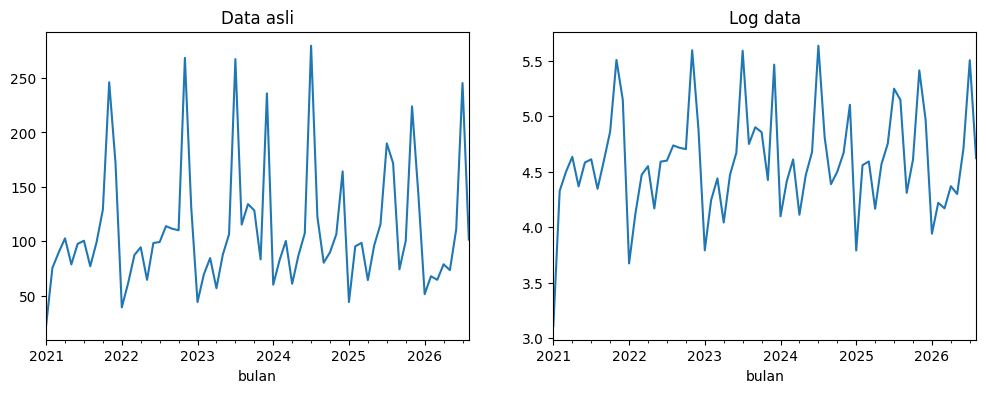

In [12]:
per_th = y[:"2025"].groupby(y[:"2025"].index.year).agg(["mean", "std"])
print(per_th.round(1))
print("Korelasi rata-rata vs simpangan baku tahunan:", round(per_th["mean"].corr(per_th["std"]), 3))
ly = np.log(y)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
y.plot(ax=ax[0], title="Data asli"); ly.plot(ax=ax[1], title="Log data"); plt.show()

## 2.8 Uji ADF dan KPSS
- **ADF**: H0 = ada akar unit (tidak stasioner). p < 0,05 → stasioner.
- **KPSS**: H0 = stasioner. p < 0,05 → tidak stasioner.

In [13]:
def uji_stasioner(seri, nama):
    seri = seri.dropna()
    adf_stat, p_adf, lag_adf, *_ = adfuller(seri, autolag="AIC")
    kpss_stat, p_kpss, *_ = kpss(seri, regression="c", nlags="auto")
    if p_adf < .05 and p_kpss >= .05:   kes = "Stasioner"
    elif p_adf >= .05 and p_kpss < .05: kes = "Tidak stasioner"
    else:                               kes = "Hasil uji tidak sepakat"
    return {"Seri": nama, "n": len(seri), "ADF stat": round(adf_stat, 3), "p ADF": round(p_adf, 4),
            "lag ADF": lag_adf, "KPSS stat": round(kpss_stat, 3), "p KPSS": round(p_kpss, 4), "Kesimpulan": kes}

hasil = pd.DataFrame([
    uji_stasioner(y, "Asli"),
    uji_stasioner(ly, "Log"),
    uji_stasioner(ly.diff(), "Log, d=1"),
    uji_stasioner(ly.diff(12), "Log, D=1 (s=12)"),
    uji_stasioner(ly.diff().diff(12), "Log, d=1 & D=1"),
])
hasil.to_csv("hasil_uji_stasioneritas.csv", index=False)
hasil

C:\Users\Athira R.F\AppData\Local\Temp\ipykernel_15060\1840425038.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, p_kpss, *_ = kpss(seri, regression="c", nlags="auto")
C:\Users\Athira R.F\AppData\Local\Temp\ipykernel_15060\1840425038.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, p_kpss, *_ = kpss(seri, regression="c", nlags="auto")
C:\Users\Athira R.F\AppData\Local\Temp\ipykernel_15060\1840425038.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, p_kpss, *_ = kpss(seri, regression="c", nlags="auto")


,Seri,n,ADF stat,p ADF,lag ADF,KPSS stat,p KPSS,Kesimpulan
0,Asli,68,-2.216,0.2007,11,0.100,0.1000,Hasil uji tidak sepakat
1,Log,68,-2.040,0.2692,11,0.133,0.1000,Hasil uji tidak sepakat
2,"Log, d=1",67,-6.847,0.0000,11,0.500,0.0417,Hasil uji tidak sepakat
3,"Log, D=1 (s=12)",56,-8.730,0.0000,0,0.129,0.1000,Stasioner
4,"Log, d=1 & D=1",55,-4.379,0.0003,9,0.500,0.0417,Hasil uji tidak sepakat


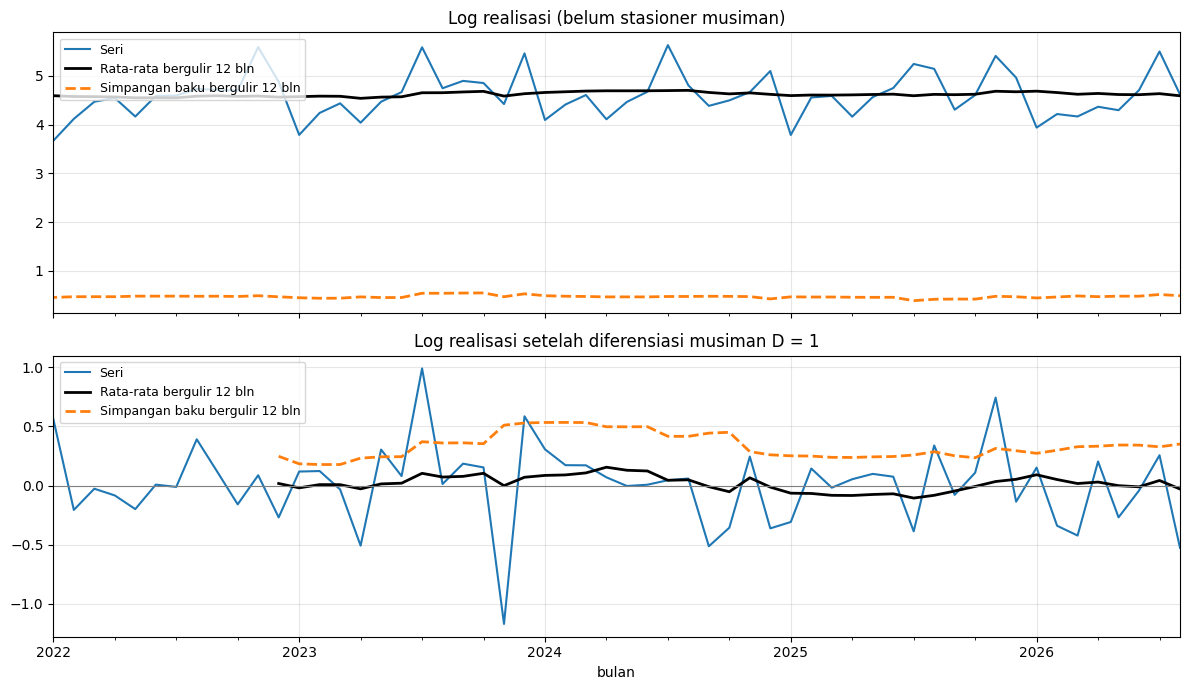

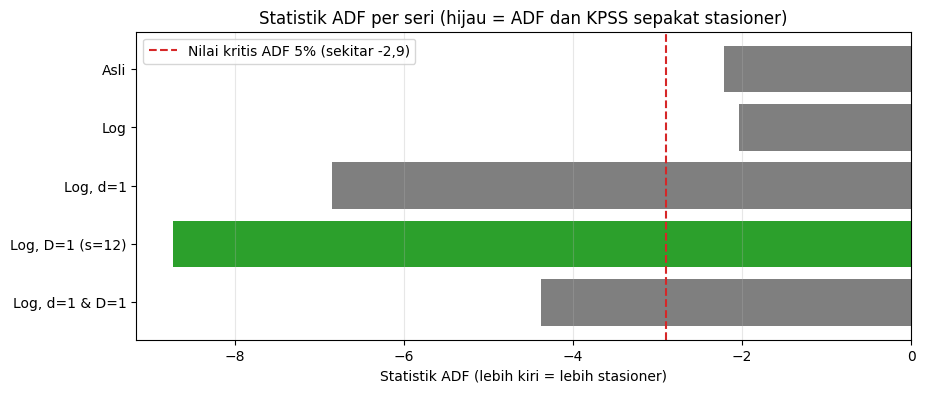

In [14]:
# Visualisasi stasioneritas: seri sebelum dan sesudah diferensiasi musiman,
# dengan rata-rata bergulir dan simpangan baku bergulir 12 bulan
seri_viz = {"Log realisasi (belum stasioner musiman)": ly,
            "Log realisasi setelah diferensiasi musiman D = 1": ly.diff(12).dropna()}
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for a, (judul, s_) in zip(ax, seri_viz.items()):
    s_.plot(ax=a, color="tab:blue", label="Seri")
    s_.rolling(12).mean().plot(ax=a, color="k", lw=2, label="Rata-rata bergulir 12 bln")
    s_.rolling(12).std().plot(ax=a, color="tab:orange", lw=2, ls="--", label="Simpangan baku bergulir 12 bln")
    a.set_title(judul); a.grid(alpha=.3); a.legend(loc="upper left", fontsize=9)
ax[1].axhline(0, color="gray", lw=.8)
plt.tight_layout(); plt.show()

# ringkasan hasil uji dalam bentuk grafik: statistik ADF vs nilai kritis 5%
fig, ax = plt.subplots(figsize=(10, 4))
warna = ["tab:green" if k == "Stasioner" else "tab:gray" for k in hasil["Kesimpulan"]]
ax.barh(hasil["Seri"], hasil["ADF stat"], color=warna)
ax.axvline(-2.9, color="tab:red", ls="--", label="Nilai kritis ADF 5% (sekitar -2,9)")
ax.invert_yaxis(); ax.set_xlabel("Statistik ADF (lebih kiri = lebih stasioner)")
ax.set_title("Statistik ADF per seri (hijau = ADF dan KPSS sepakat stasioner)"); ax.legend(); ax.grid(alpha=.3, axis="x")
plt.show()

## 2.9 Stasioneritas musiman
ADF biasa tidak menguji akar unit musiman. Petunjuknya dilihat dari ACF di lag 12, 24, 36: jika tinggi dan meluruh lambat, perlu D = 1.

ACF log(y) di lag musiman: {12: 0.589, 24: 0.377, 36: 0.304}


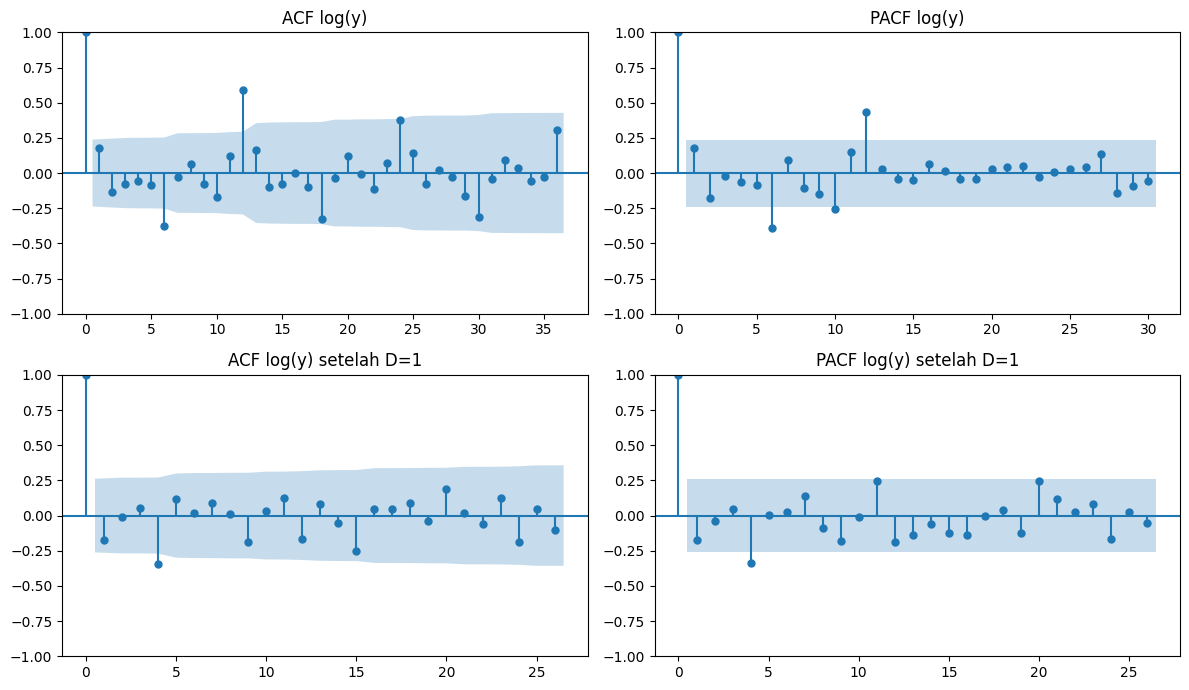

In [15]:
from statsmodels.tsa.stattools import acf
r = acf(ly, nlags=36)
print("ACF log(y) di lag musiman:", {k: round(r[k], 3) for k in (12, 24, 36)})

fig, ax = plt.subplots(2, 2, figsize=(12, 7))
plot_acf(ly, lags=36, ax=ax[0, 0]); ax[0, 0].set_title("ACF log(y)")
plot_pacf(ly, lags=30, ax=ax[0, 1], method="ywm"); ax[0, 1].set_title("PACF log(y)")
w = ly.diff(12).dropna()
plot_acf(w, lags=26, ax=ax[1, 0]); ax[1, 0].set_title("ACF log(y) setelah D=1")
plot_pacf(w, lags=26, ax=ax[1, 1], method="ywm"); ax[1, 1].set_title("PACF log(y) setelah D=1")
plt.tight_layout(); plt.show()

## 2.10 Identifikasi orde awal SARIMA
Panduan membaca plot ACF/PACF setelah D = 1:
- **p (AR non-musiman):** PACF terpotong di lag 1–2.
- **q (MA non-musiman):** ACF terpotong di lag 1–2.
- **P (AR musiman):** PACF signifikan di lag 12.
- **Q (MA musiman):** ACF signifikan negatif di lag 12 (umum setelah diferensiasi musiman).

Dugaan awal yang dipakai di Progres 3: **SARIMA(p, 0, q)(P, 1, Q)₁₂ pada log(y)**, dengan p, q, P, Q ∈ {0, 1} dipilih berdasarkan AIC.

## 2.11 Pembagian data latih dan uji
12 bulan terakhir data riil dijadikan data uji agar setiap bulan kalender muncul tepat sekali.

In [16]:
AWAL_UJI = "2025-09-01"            # data uji: Sep 2025 – Agu 2026 (12 bulan)
train, test = y[y.index < AWAL_UJI], y[y.index >= AWAL_UJI]
print(len(train), "bulan latih |", len(test), "bulan uji")

56 bulan latih | 12 bulan uji


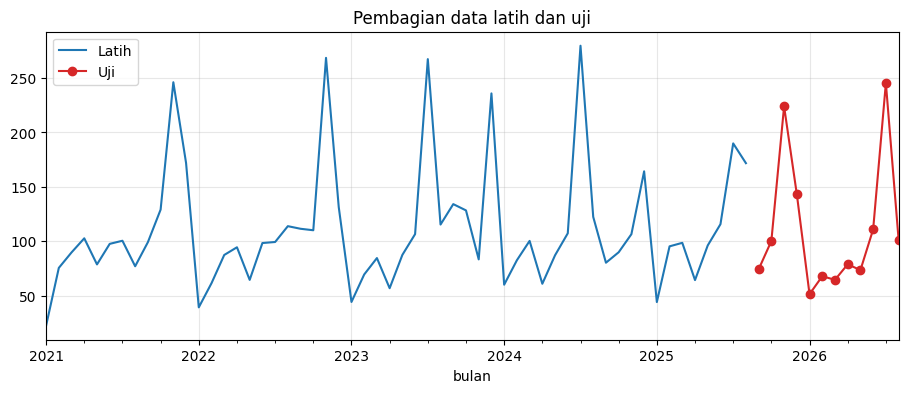

{'awal_uji': '2025-09-01', 'n_latih': 56, 'n_uji': 12, 'transformasi': 'log', 'd': 0, 'D': 1, 's': 12}
Tersimpan: c:\Users\Athira R.F\Documents\Python Programming\kuliah\magang\hasil_uji_stasioneritas.csv
Tersimpan: c:\Users\Athira R.F\Documents\Python Programming\kuliah\magang\pembagian_data.json


In [17]:
fig, ax = plt.subplots()
train.plot(ax=ax, label="Latih", color="tab:blue"); test.plot(ax=ax, label="Uji", color="tab:red", marker="o")
ax.set_title("Pembagian data latih dan uji"); ax.legend(); ax.grid(alpha=.3); plt.show()

pembagian = {"awal_uji": AWAL_UJI, "n_latih": len(train), "n_uji": len(test),
             "transformasi": "log", "d": 0, "D": 1, "s": 12}
json.dump(pembagian, open("pembagian_data.json", "w"), indent=2)
print(pembagian)
unduh("hasil_uji_stasioneritas.csv", "pembagian_data.json")